## Q1. Which product categories generate the most revenue?

Category
Electronics       30023661.91
Home & Kitchen     4160499.08
Clothing           2523858.05
Sports             2064694.78
Beauty             1139694.27
Name: Revenue, dtype: float64


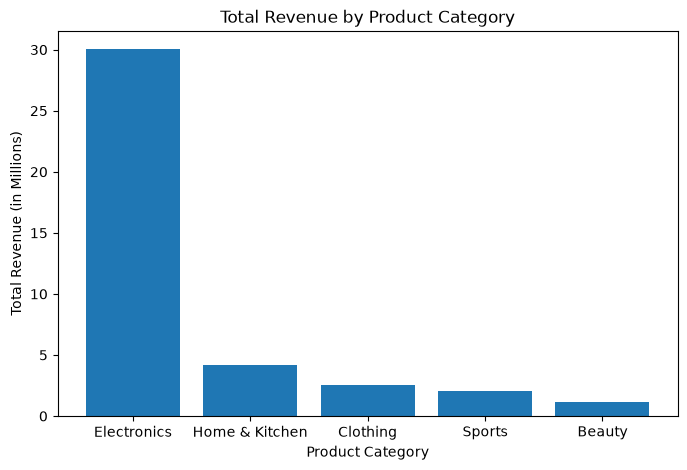

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('Raw_Data_and_Business_Problem.xlsx', sheet_name='Raw_Data')

category_revenue = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
print(category_revenue.round(2))

plt.figure(figsize=(8, 5))
plt.bar(category_revenue.index, category_revenue.values / 1000000)
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (in Millions)')
plt.show()

## Q2. Which cities and sales channels perform best?

City
Chennai       9349613.65
Bengaluru     8274961.93
Hyderabad     6659545.01
Coimbatore    6266331.27
Hosur         5740102.77
Madurai       3621853.46
Name: Revenue, dtype: float64

Channel
Mobile App     14578514.50
Website        14438164.12
Marketplace    10895729.47
Name: Revenue, dtype: float64


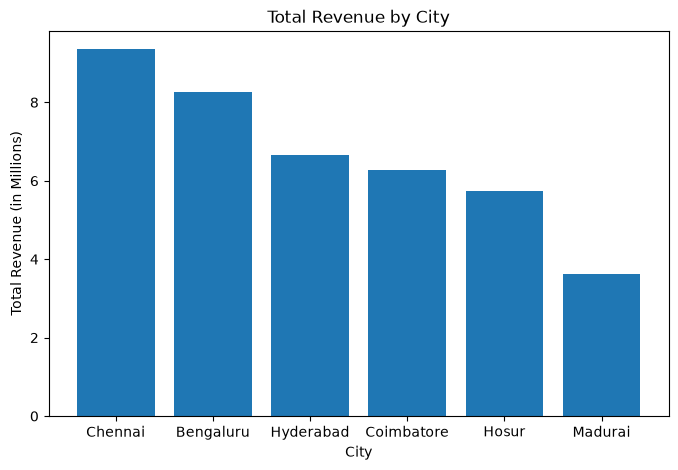

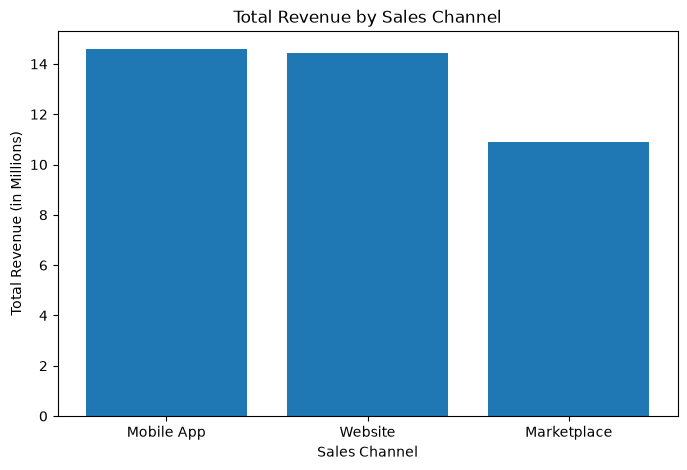

In [3]:
city_revenue = df.groupby('City')['Revenue'].sum().sort_values(ascending=False)
channel_revenue = df.groupby('Channel')['Revenue'].sum().sort_values(ascending=False)

print(city_revenue.round(2))
print()
print(channel_revenue.round(2))

plt.figure(figsize=(8, 5))
plt.bar(city_revenue.index, city_revenue.values / 1000000)
plt.title('Total Revenue by City')
plt.xlabel('City')
plt.ylabel('Total Revenue (in Millions)')
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(channel_revenue.index, channel_revenue.values / 1000000)
plt.title('Total Revenue by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Revenue (in Millions)')
plt.show()

## Q3. How do discounts affect revenue?

              Orders  Total_Revenue  Avg_Revenue_Per_Order
Discount_Pct                                              
0.0              425     9519216.99               22398.16
5.0              388     7699439.90               19843.92
10.0             499    10339737.50               20720.92
15.0             369     7310298.25               19811.11
20.0             202     3060305.40               15150.03
25.0              97     1655516.92               17067.18


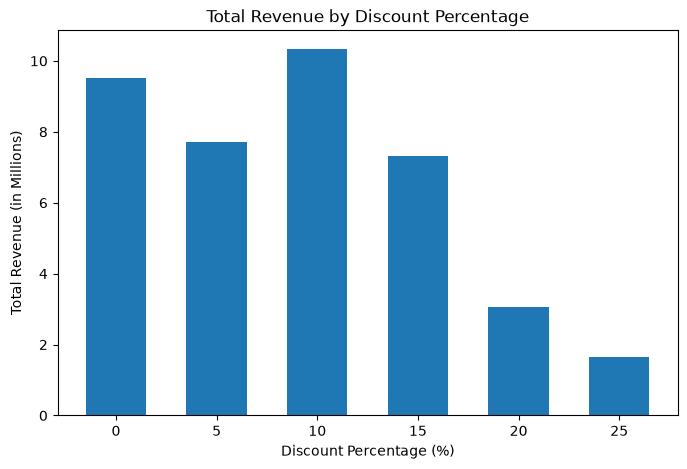

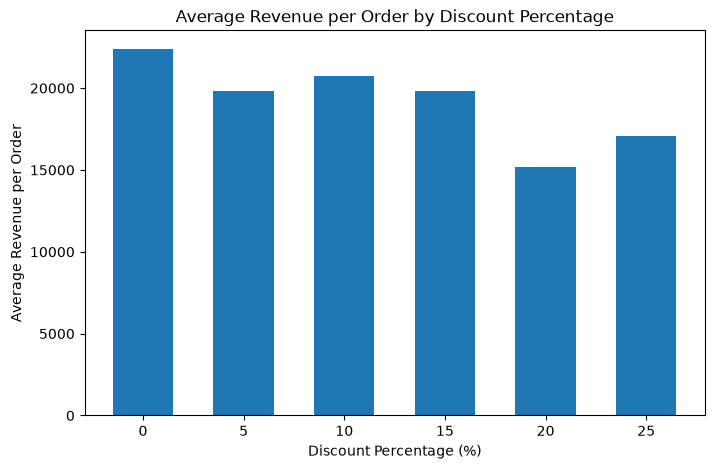

In [4]:
discount = df.groupby('Discount_Pct')['Revenue'].agg(['count', 'sum', 'mean'])
discount.columns = ['Orders', 'Total_Revenue', 'Avg_Revenue_Per_Order']
print(discount.round(2))

plt.figure(figsize=(8, 5))
plt.bar(discount.index, discount['Total_Revenue'] / 1000000, width=3)
plt.xticks(discount.index)
plt.title('Total Revenue by Discount Percentage')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Total Revenue (in Millions)')
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(discount.index, discount['Avg_Revenue_Per_Order'], width=3)
plt.xticks(discount.index)
plt.title('Average Revenue per Order by Discount Percentage')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Average Revenue per Order')
plt.show()

## Q4. Which payment methods are most commonly used?

Payment_Method
UPI                 861
Credit Card         521
Debit Card          367
Cash on Delivery    251
Name: count, dtype: int64


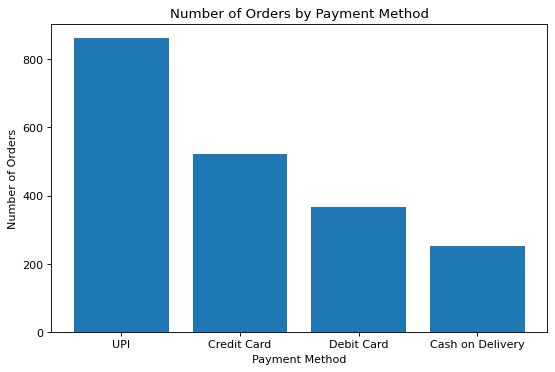

In [4]:
payment_count = df['Payment_Method'].value_counts()
print(payment_count)

plt.figure(figsize=(8, 5))
plt.bar(payment_count.index, payment_count.values)
plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.show()

## Q5. What is the return rate?

Total orders   : 2000
Returned orders: 177
Return rate    : 8.85 %


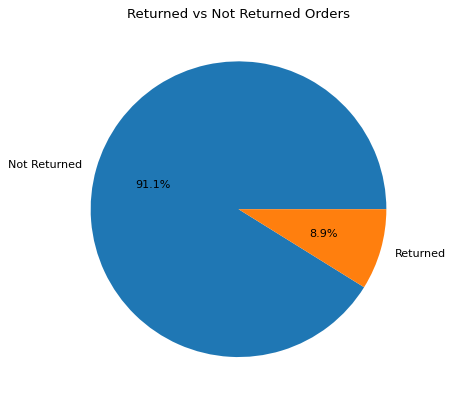

In [5]:
total_orders = len(df)
returned_orders = (df['Returned'] == 'Yes').sum()
return_rate = returned_orders / total_orders * 100

print('Total orders   :', total_orders)
print('Returned orders:', returned_orders)
print('Return rate    :', round(return_rate, 2), '%')

returned_count = df['Returned'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(returned_count.values, labels=['Not Returned', 'Returned'], autopct='%1.1f%%')
plt.title('Returned vs Not Returned Orders')
plt.show()

## Q6. Which months have the highest revenue?

Month
2025-01    2886423.81
2025-02    3042578.74
2025-03    3846064.40
2025-04    3879267.81
2025-05    3070300.66
2025-06    3279095.99
2025-07    2667905.09
2025-08    3838469.90
2025-09    3043132.53
2025-10    3469588.57
2025-11    3134233.86
2025-12    3755346.73
Name: Revenue, dtype: float64

Top 3 months:
Month
2025-04    3879267.81
2025-03    3846064.40
2025-08    3838469.90
Name: Revenue, dtype: float64


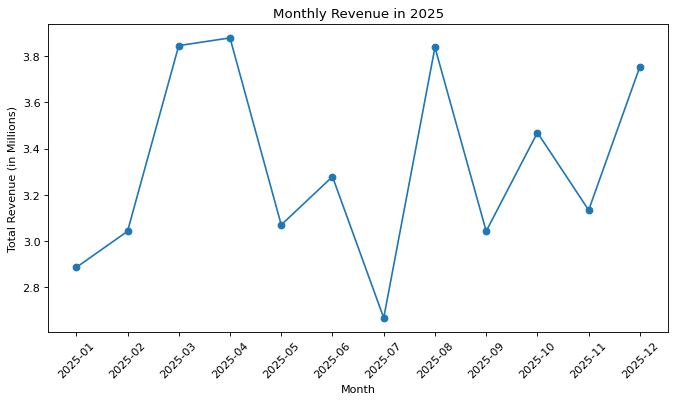

In [6]:
df['Month'] = df['Order_Date'].dt.to_period('M').astype(str)

monthly_revenue = df.groupby('Month')['Revenue'].sum()
print(monthly_revenue.round(2))

print()
print('Top 3 months:')
print(monthly_revenue.sort_values(ascending=False).head(3).round(2))

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values / 1000000, marker='o')
plt.title('Monthly Revenue in 2025')
plt.xlabel('Month')
plt.ylabel('Total Revenue (in Millions)')
plt.xticks(rotation=45)
plt.show()

## Q7. What operational factors may be linked to customer ratings?

               count  mean
Delivery_Days             
1.0              415  3.94
2.0              359  3.98
3.0              406  3.94
4.0              354  3.95
5.0              228  3.95
6.0              108  4.03
7.0               34  3.98
8.0               12  3.87

Correlation (Delivery_Days, Customer_Rating): 0.015


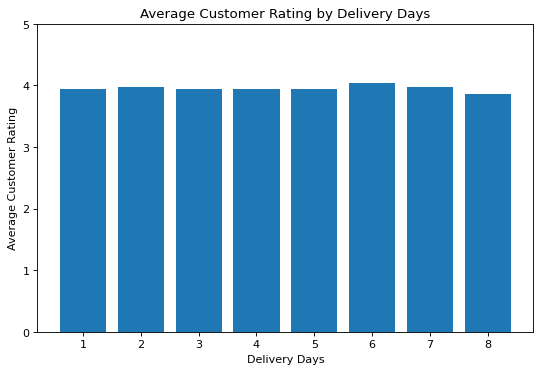

In [7]:
# Delivery days vs rating
delivery = df.groupby('Delivery_Days')['Customer_Rating'].agg(['count', 'mean'])
delivery = delivery[delivery['count'] >= 10]
print(delivery.round(2))

print()
print('Correlation (Delivery_Days, Customer_Rating):', round(df['Delivery_Days'].corr(df['Customer_Rating']), 3))

plt.figure(figsize=(8, 5))
plt.bar(delivery.index, delivery['mean'])
plt.ylim(0, 5)
plt.title('Average Customer Rating by Delivery Days')
plt.xlabel('Delivery Days')
plt.ylabel('Average Customer Rating')
plt.show()

In [8]:
# Returned, Channel and Payment_Method vs rating
for col in ['Returned', 'Channel', 'Payment_Method']:
    print(df.groupby(col)['Customer_Rating'].mean().round(2))
    print()

Returned
No     3.96
Yes    3.93
Name: Customer_Rating, dtype: float64

Channel
Marketplace    3.95
Mobile App     3.94
Website        3.98
Name: Customer_Rating, dtype: float64

Payment_Method
Cash on Delivery    3.90
Credit Card         3.95
Debit Card          3.96
UPI                 3.98
Name: Customer_Rating, dtype: float64

